# Notebook 3 - Route 7 arrival-delay research

**Goal:** clean Route 7 records, place actual and scheduled arrivals side by side, and fit a simple model of arrival delay.

We assume these files are already **in the same folder as this notebook**:

- `RTS_Route7_March2023.xlsx` — recorded bus stop visits.
- `RTS_GTFS_Spring2023.zip` — historical schedule source; leave it zipped.

Run cells in order with **Shift + Enter**. We will work only with **Route 7**. Each stage states what it starts with, what it does, and what it produces. Outputs are dataframes in memory; this notebook does not overwrite source files.

We start with the original **uncleaned** workbook. All cleaning, schedule preparation, and joining happen inside this notebook. There is no prepared CSV to load. The schedule is a separate input because the actual-arrival workbook does not contain published scheduled times.

## Research workflow

| Stage | Question | Output |
| --- | --- | --- |
| 1. Load and inspect | What records do we have? | Original dataframe and data overview. |
| 2. Clean and examine buses | Which records need review, and how are visits organized? | Cleaned copy, flags, and bus-day views. |
| 3. Prepare and link schedules | Which scheduled visit might each actual visit belong to? | Provisional scheduled-versus-actual table. |
| 4. Prepare modeling data | What is the target, what can predict it, and which dates are held out? | Delay target, date split, and encoded predictor tables. |
| 5. Fit and validate regression | Does regression improve on the schedule? | Predictions, validation errors, and plots. |
| 6. Assess and document | Which predictors are justified and what remains uncertain? | Regression diagnostics and research decisions. |

**Suggested stopping points:** finish Stage 3 to review schedule assignments; finish Stage 4 to review predictors before fitting. Stage 6 diagnostics can be covered separately.

**Research status:** time-based schedule assignments are provisional. Results are exploratory research on that linked subset. Verify assignments and assess matching-related selection bias before making claims about overall RTS reliability.

## Extension added after Stage 6
Stages 1-6 are the existing Notebook 2.5 workflow. Continue below them for the new work; there is no second loading, initial cleaning, timetable merge, or introductory regression section.

| New stage | Purpose |
|---|---|
| 7 | Check journey evidence and refine which arrival labels we can defend |
| 8 | Preserve held records and flag unusual delays without deleting them |
| 9 | Compare a median baseline, linear regression, and ridge using whole-date folds |
| 10 | Explain errors, summarize findings, and choose a route extension |

The extension narrows the earlier provisional sample to 304 nonterminal Health Department labels, including 232 training and 72 validation observations. Refit and compare all methods on that same population. Earlier Stage 5 scores use a different population and are not directly comparable.


## Stage 1 — Load and inspect the source data

**Input:** original Route 7 Excel workbook.  
**Purpose:** understand rows, columns, coverage, and missing values.  
**Output:** `raw`, an unchanged source dataframe and initial overview.

### 1.1 Import libraries

- `pandas` works with tables.
- `numpy` helps with calculations.
- `matplotlib` makes plots.
- `statsmodels` fits linear regression and provides its diagnostic measures.
- `zipfile` reads the schedule ZIP; it comes with Python.

If a library is missing, install it into your selected Python environment and restart the kernel.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import zipfile
from IPython.display import display

### 1.2 Load the original Route 7 workbook

This is the same uncleaned file used in Notebook 1. We will modify a dataframe copy, not overwrite your original Excel file.

In [2]:
raw = pd.read_excel("RTS_Route7_March2023.xlsx", engine="openpyxl")
display(raw.head())


,Route,Stop ID,Stop Name,Stop Seq ID,Day of Week,Date,Arrive,Passenger On,Passenger Off,Passenger Load,Passenger Miles,Interstop Distance,Bus,Lat.,Long.
0,7-Downtown Station To Eastwood Meadows,1,Rosa Parks RTS Downtown Station,0,Wednesday,2023-03-01,06:05:27,7,0,7,0.000,0.00,2105,29.64656,-82.32236
1,7-Downtown Station To Eastwood Meadows,292,The Cotton Club,1,Wednesday,2023-03-01,06:06:53,0,0,7,3.873,0.55,2105,29.64581,-82.31482
2,7-Downtown Station To Eastwood Meadows,293,Mt Moriah Baptist Church,2,Wednesday,2023-03-01,06:07:12,0,0,7,1.090,0.16,2105,29.64579,-82.31194
3,7-Downtown Station To Eastwood Meadows,294,Tools for Schools,3,Wednesday,2023-03-01,06:08:46,0,0,7,0.703,0.10,2105,29.64578,-82.30989
4,7-Downtown Station To Eastwood Meadows,295,Williams Elementary School,4,Wednesday,2023-03-01,06:09:00,0,0,7,0.723,0.10,2105,29.64577,-82.30790


### 1.3 Understand the columns and inspect coverage

| Actual-data column | Meaning |
| --- | --- |
| `Bus` | Vehicle ID; one bus can make many journeys. |
| `Date` and `Arrive` | Recorded day and arrival clock time. |
| `Stop ID` | Location label, not the stop's position in the route. |
| `Stop Seq ID` | Position in a recorded stop sequence; can restart. |
| Passenger/distance/location fields | Useful context, but not needed for our first model. |

The schedule has `trip_id` for the scheduled journey, `direction_id`, stop information, and `scheduled_arrival`.

**Discuss:** why could joining only on Stop ID attach many different scheduled times to one observation?

In [3]:
print("Actual-data shape:", raw.shape)
print("Buses:", raw["Bus"].nunique(), "Dates:", raw["Date"].nunique())
display(raw.isna().sum().to_frame("missing_values"))

Actual-data shape: (14685, 15)
Buses: 5 Dates: 17


,missing_values
Route,0
Stop ID,0
Stop Name,0
Stop Seq ID,0
Day of Week,0
Date,0
Arrive,0
Passenger On,0
Passenger Off,0
Passenger Load,0


## Stage 2 — Clean records and examine individual buses

**Input:** `raw`.  
**Purpose:** standardize fields, flag uncertainty, and inspect visits by vehicle/date.  
**Output:** `data`, a working copy with timestamps, source references, and review flags; `bus_summary` and `one_bus_day` for inspection.

### 2.1 Create a working copy and standardize fields

Keep the original unchanged. We add a source-row reference, remove only exact copies of original rows, and create readable column names. Repeated date/bus/stop/time combinations that disagree in other fields are **not** silently collapsed.

Stop IDs become text labels. Dates and times become timestamps so we can subtract them. An invalid clock time becomes missing, rather than being guessed.

In [4]:
data = raw.copy()
data["source_row"] = data.index
data = data.drop_duplicates(subset=raw.columns.tolist()).copy()
data["bus_id"] = data["Bus"].astype("string")
data["stop_id"] = data["Stop ID"].astype("string").str.replace(r"\.0$", "", regex=True)
data["stop_sequence"] = pd.to_numeric(data["Stop Seq ID"], errors="coerce")
data["service_date"] = pd.to_datetime(data["Date"], errors="coerce").dt.normalize()
clock = pd.to_timedelta(data["Arrive"].astype(str), errors="coerce")
clock = clock.where((clock >= pd.Timedelta(0)) & (clock < pd.Timedelta(days=1)))
data["actual_arrival"] = data["service_date"] + clock

print("Rows before:", len(raw), "After exact-copy rule:", len(data))
display(data[["source_row", "bus_id", "stop_id", "stop_sequence", "actual_arrival"]].head())

Rows before: 14685 After exact-copy rule: 14685


,source_row,bus_id,stop_id,stop_sequence,actual_arrival
0,0,2105,1,0,2023-03-01 06:05:27
1,1,2105,292,1,2023-03-01 06:06:53
2,2,2105,293,2,2023-03-01 06:07:12
3,3,2105,294,3,2023-03-01 06:08:46
4,4,2105,295,4,2023-03-01 06:09:00


### 2.2 Flag uncertain observations

We flag missing identifiers/timestamps, unusual sequence/stop codes, conflicting event keys, and tied timestamps within a bus-day. Tied terminal records need separate interpretation; this first exercise leaves them out of automatic matching.

We retain the flags and row counts so we can explain what was excluded.

In [5]:
bad_fields = (
    data[["bus_id", "stop_id", "stop_sequence", "actual_arrival"]].isna().any(axis=1)
    | (data["stop_sequence"] < 0) | (data["stop_sequence"] % 1 != 0)
    | (data["stop_sequence"] == 999) | data["stop_id"].eq("9999").fillna(True)
)
repeated_key = data.duplicated(["bus_id", "service_date", "stop_id", "actual_arrival"], keep=False)
tied_time = data.duplicated(["bus_id", "service_date", "actual_arrival"], keep=False)
data["needs_review"] = bad_fields | repeated_key | tied_time

display(pd.Series({"invalid_fields": int(bad_fields.sum()),
                   "repeated_key_rows": int(repeated_key.sum()),
                   "tied_time_rows": int(tied_time.sum())}).to_frame("flagged_rows"))
display(data.loc[data["needs_review"], ["source_row", "bus_id", "stop_id", "actual_arrival"]].head(6))

,flagged_rows
invalid_fields,126
repeated_key_rows,880
tied_time_rows,907


,source_row,bus_id,stop_id,actual_arrival
31,31,2105,326,2023-03-01 06:31:05
32,32,2105,326,2023-03-01 06:31:05
63,63,2105,1,2023-03-01 06:51:52
64,64,2105,1,2023-03-01 06:51:52
95,95,2105,326,2023-03-01 07:30:20
96,96,2105,327,2023-03-01 07:30:20


### 2.3 Summarize each bus and date

`groupby` summarizes each vehicle/date separately. This does not create a separate model for every bus. The cleaned records will later remain together in one modeling table.

In [6]:
bus_summary = data.groupby(["bus_id", "service_date"]).agg(
    recorded_visits=("source_row", "size"),
    first_arrival=("actual_arrival", "min"),
    last_arrival=("actual_arrival", "max"),
).reset_index()
display(bus_summary.head(10))

,bus_id,service_date,recorded_visits,first_arrival,last_arrival
0,1807,2023-03-14,892,2023-03-14 05:52:03,2023-03-14 19:51:52
1,2005,2023-03-10,830,2023-03-10 07:06:55,2023-03-10 19:52:39
2,2104,2023-03-16,903,2023-03-16 06:01:21,2023-03-16 19:48:46
3,2104,2023-03-21,904,2023-03-21 06:03:01,2023-03-21 19:51:33
4,2104,2023-03-23,717,2023-03-23 06:04:42,2023-03-23 16:58:33
5,2105,2023-03-01,903,2023-03-01 06:05:27,2023-03-01 19:52:05
6,2105,2023-03-02,892,2023-03-02 06:04:00,2023-03-02 19:52:35
7,2105,2023-03-03,641,2023-03-03 06:02:06,2023-03-03 15:54:41
8,2105,2023-03-06,892,2023-03-06 06:01:55,2023-03-06 19:51:41
9,2105,2023-03-07,892,2023-03-07 06:05:22,2023-03-07 19:52:14


### 2.4 Follow one bus through a day

Change the bus/date below to explore another example. Look for repeated stop sequences and possible journey boundaries. This cell is for understanding the data, not assigning ground-truth trip IDs.

In [7]:
bus = "2105"
day = pd.Timestamp("2023-03-01")
one_bus_day = data.loc[(data["bus_id"] == bus) & (data["service_date"] == day)]
one_bus_day = one_bus_day.sort_values(["actual_arrival", "source_row"])
display(one_bus_day[["source_row", "Stop Name", "stop_id", "stop_sequence", "actual_arrival"]].head(40))

,source_row,Stop Name,stop_id,stop_sequence,actual_arrival
0,0,Rosa Parks RTS Downtown Station,1,0,2023-03-01 06:05:27
1,1,The Cotton Club,292,1,2023-03-01 06:06:53
2,2,Mt Moriah Baptist Church,293,2,2023-03-01 06:07:12
3,3,Tools for Schools,294,3,2023-03-01 06:08:46
4,4,Williams Elementary School,295,4,2023-03-01 06:09:00
5,5,Eastbound SE 7th Avenue @ SE 15th Street,297,5,2023-03-01 06:09:15
6,6,Northbound SE 15th Street @ SE 3rd Avenue,96,6,2023-03-01 06:09:51
7,7,Fast Eddies Restaurant,300,7,2023-03-01 06:10:25
8,8,Eastbound University Avenue @ SE 15th Street,301,8,2023-03-01 06:11:05
9,9,Alachua County School Board Administration Annex,303,9,2023-03-01 06:11:25


## Stage 3 — Prepare the historical schedule and propose matches

**Input:** cleaned/flagged actual visits in `data` and the historical GTFS ZIP.  
**Purpose:** attach a plausible scheduled visit without silently accepting ambiguous assignments.  
**Output:** `schedule`, `matched` (provisional links), and `conflict_review` (assignments set aside).

### 3.1 Read the schedule source tables

The workbook has actual arrivals, so we also need RTS's published timetable. GTFS stores that timetable as linked text tables inside a ZIP. We read those tables directly; there is no prepared schedule CSV.

Focus on what each table contributes to the linkage. The helper only reads source tables; it does not clean or approve actual observations.

- `trips`: route, direction, scheduled trip, and service identifiers.
- `stop_times`: ordered stops and published times for each trip.
- `calendar` and `exceptions`: which service runs on a date.
- `stops`: stop names.

Read IDs as text and strip whitespace so joins match correctly.

In [8]:
def read_schedule_table(filename):
    with zipfile.ZipFile("RTS_GTFS_Spring2023.zip") as archive:
        table = pd.read_csv(archive.open(filename), dtype=str, keep_default_na=False)
    table.columns = table.columns.str.strip()
    return table.apply(lambda column: column.str.strip())

trips = read_schedule_table("trips.txt")
stop_times = read_schedule_table("stop_times.txt")
calendar = read_schedule_table("calendar.txt")
exceptions = read_schedule_table("calendar_dates.txt")
stops = read_schedule_table("stops.txt")

route7_trips = trips.loc[trips["route_id"] == "7"]
display(route7_trips[["trip_id", "direction_id", "service_id", "trip_headsign"]].head())

,trip_id,direction_id,service_id,trip_headsign
919,5007001,0,SWB,To Eastwood Meadows
920,5007003,0,SWB,To Eastwood Meadows
921,5007005,0,SWB,To Eastwood Meadows
922,5007007,0,SWB,To Eastwood Meadows
923,5007009,0,SWB,To Eastwood Meadows


### 3.2 Build the date-specific Route 7 timetable

First join scheduled trips to their stop times. Keep only explicit published arrival times; blank intermediate stops must not become invented schedule values.

Then, for each observed date, select the service IDs allowed by the calendar and its date exceptions. Add that date to each scheduled clock time. GTFS can represent times beyond 24:00 for overnight service.

In [9]:
route7_times = route7_trips.merge(stop_times, on="trip_id", validate="one_to_many")
route7_times = route7_times.loc[route7_times["arrival_time"] != ""].copy()
route7_times = route7_times.merge(stops[["stop_id", "stop_name"]], on="stop_id", validate="many_to_one")

scheduled_days = []
for date in sorted(data["service_date"].dropna().unique()):
    date = pd.Timestamp(date)
    date_code = date.strftime("%Y%m%d")
    active = set(calendar.loc[
        (calendar["start_date"] <= date_code) & (calendar["end_date"] >= date_code)
        & (calendar[date.day_name().lower()] == "1"), "service_id"
    ])
    for change in exceptions.loc[exceptions["date"] == date_code].itertuples(index=False):
        if change.exception_type == "1":
            active.add(change.service_id)
        elif change.exception_type == "2":
            active.discard(change.service_id)
    day_schedule = route7_times.loc[route7_times["service_id"].isin(active)].copy()
    day_schedule["service_date"] = date
    day_schedule["scheduled_arrival"] = date + pd.to_timedelta(day_schedule["arrival_time"])
    scheduled_days.append(day_schedule)

schedule = pd.concat(scheduled_days, ignore_index=True)
schedule["stop_sequence"] = pd.to_numeric(schedule["stop_sequence"])
display(schedule[["service_date", "trip_id", "direction_id", "stop_id", "scheduled_arrival"]].head())

,service_date,trip_id,direction_id,stop_id,scheduled_arrival
0,2023-03-01,4059089,0,1,2023-03-01 06:00:00
1,2023-03-01,4059089,0,107,2023-03-01 06:08:00
2,2023-03-01,4059089,0,326,2023-03-01 06:20:00
3,2023-03-01,4059090,0,1,2023-03-01 07:00:00
4,2023-03-01,4059090,0,107,2023-03-01 07:08:00


### 3.3 Check stop order and direction before linking

**First check the schedule pattern.** A location can occur in different directions at different sequence positions. We match both Stop ID and stop order, then use service date and scheduled time to distinguish repeated trips.

This depends on recorded order meaning the same thing as schedule order. Inspect the table below and verify several examples against surrounding stop names before trusting it. Sequence agreement is supporting evidence, not proof of a trip assignment.

In [10]:
pattern_check = schedule[["stop_id", "stop_name", "stop_sequence", "direction_id"]].drop_duplicates()
display(pattern_check.sort_values(["direction_id", "stop_sequence"]))

,stop_id,stop_name,stop_sequence,direction_id
0,1,Rosa Parks RTS Downtown Station,0,0
1,107,Health Department,13,0
2,326,Eastwood Meadows,31,0
42,326,Eastwood Meadows,0,1
43,107,Health Department,18,1
44,1,Rosa Parks RTS Downtown Station,31,1


### 3.4 Generate and filter candidate schedule links

The first merge intentionally creates candidate scheduled visits for each unflagged observation on the same date, stop, and sequence position. There may be several hourly trips.

The initial research linkage rule keeps candidates within **20 minutes** of the recorded arrival. Keep an observation only if exactly one scheduled candidate fits. This does **not** establish correctness: a severely delayed trip could be assigned to the wrong hour, and delays beyond the window are excluded by design.

Do not use the resulting model scores as unbiased evidence of overall schedule reliability. Independent journey review is needed before project conclusions.

In [11]:
observations = data.loc[~data["needs_review"]].copy()
possible = observations.merge(
    schedule, on=["service_date", "stop_id", "stop_sequence"], how="inner"
)
possible["matching_gap_minutes"] = (
    possible["actual_arrival"] - possible["scheduled_arrival"]
).dt.total_seconds().abs() / 60

MATCH_WINDOW_MINUTES = 20
possible = possible.loc[possible["matching_gap_minutes"] <= MATCH_WINDOW_MINUTES].copy()
possible["candidate_count"] = possible.groupby("source_row")["source_row"].transform("size")
matched = possible.loc[possible["candidate_count"] == 1].copy()

# Two observations must not silently claim the same scheduled stop visit.
conflict = matched.duplicated(["service_date", "trip_id", "stop_sequence"], keep=False)
conflict_review = matched.loc[conflict].copy()
matched = matched.loc[~conflict].copy()
matched["match_status"] = "provisional — requires journey review"

print("Unflagged recorded visits:", len(observations))
print("Visits with one non-conflicting proposed schedule match:", len(matched))
print("Conflicting assignments set aside:", len(conflict_review))
display(matched[["source_row", "bus_id", "stop_id", "direction_id", "trip_id",
                 "scheduled_arrival", "actual_arrival"]].head(10))

Unflagged recorded visits: 13652
Visits with one non-conflicting proposed schedule match: 416
Conflicting assignments set aside: 0


,source_row,bus_id,stop_id,direction_id,trip_id,scheduled_arrival,actual_arrival
0,0,2105,1,0,4059089,2023-03-01 06:00:00,2023-03-01 06:05:27
14,13,2105,107,0,4059089,2023-03-01 06:08:00,2023-03-01 06:13:20
28,50,2105,107,1,4059101,2023-03-01 06:40:00,2023-03-01 06:41:12
43,77,2105,107,0,4059090,2023-03-01 07:08:00,2023-03-01 07:15:59
57,114,2105,107,1,4059102,2023-03-01 07:40:00,2023-03-01 07:40:57
72,141,2105,107,0,4059091,2023-03-01 08:08:00,2023-03-01 08:13:59
86,178,2105,107,1,4059103,2023-03-01 08:40:00,2023-03-01 08:42:34
101,205,2105,107,0,4059092,2023-03-01 09:08:00,2023-03-01 09:11:49
115,242,2105,107,1,4059104,2023-03-01 09:40:00,2023-03-01 09:40:50
130,269,2105,107,0,4059093,2023-03-01 10:08:00,2023-03-01 10:09:53


### 3.5 Review linkage quality before proceeding

Choose at least five examples across buses/dates. Check their source records, neighboring stops, direction, and scheduled journey. Inspect rejected cases too. At terminals, confirm whether the recorded time really means arrival rather than departure.

Only explicit timed stops can match; intermediate stops with no published time remain out of this exercise. Flagged visits and ambiguous/conflicting assignments are also excluded. These choices can bias which service is represented.

The following stages run exploratory analysis on **provisional matches**. Completing five checks is a starting point, not approval of the full dataset. Record your review findings in Stage 6 and revisit the matching rules if the evidence is weak.

**Stage 3 checkpoint:** you should be able to explain exactly how one actual visit received its scheduled trip and why that assignment might be wrong.

## Stage 4 — Define the target, hold out dates, and prepare predictors

**Input:** provisional linked visits in `matched`.  
**Purpose:** define the prediction task and build consistent inputs without using future outcomes as predictors.  
**Output:** `delay_minutes`, `train`, `validation`, `PREDICTORS`, `X_train`, and `X_validation`. Final-test dates remain reserved.

### 4.1 Calculate the target: delay in minutes

**Delay = actual arrival − scheduled arrival.** Positive means late; negative means early. Our model predicts this difference. Trusting the schedule is equivalent to predicting zero delay.

In [12]:
matched["delay_minutes"] = (
    matched["actual_arrival"] - matched["scheduled_arrival"]
).dt.total_seconds() / 60
display(matched[["stop_id", "scheduled_arrival", "actual_arrival", "delay_minutes"]].head())

,stop_id,scheduled_arrival,actual_arrival,delay_minutes
0,1,2023-03-01 06:00:00,2023-03-01 06:05:27,5.450000
14,107,2023-03-01 06:08:00,2023-03-01 06:13:20,5.333333
28,107,2023-03-01 06:40:00,2023-03-01 06:41:12,1.200000
43,107,2023-03-01 07:08:00,2023-03-01 07:15:59,7.983333
57,107,2023-03-01 07:40:00,2023-03-01 07:40:57,0.950000


### 4.2 Reserve chronological training, validation, and test dates

Use Route 7's first 10 observed dates for training, the next 3 for validation, and the last 4 for the final test. Keep whole dates together across all buses. We will not score the final test in this notebook.

Fix this split before choosing features based on their relationship with delay. It does not undo the earlier matching selection bias.

In [13]:
dates = sorted(data["service_date"].dropna().unique())
train = matched.loc[matched["service_date"].isin(dates[:10])].copy()
validation = matched.loc[matched["service_date"].isin(dates[10:13])].copy()

print("Training dates:", pd.to_datetime(dates[:10]).strftime("%m-%d").tolist())
print("Validation dates:", pd.to_datetime(dates[10:13]).strftime("%m-%d").tolist())
print("Reserved test dates:", pd.to_datetime(dates[13:]).strftime("%m-%d").tolist())
print("Training rows:", len(train), "Validation rows:", len(validation))

Training dates: ['03-01', '03-02', '03-03', '03-06', '03-07', '03-08', '03-09', '03-10', '03-13', '03-14']
Validation dates: ['03-15', '03-16', '03-17']
Reserved test dates: ['03-20', '03-21', '03-22', '03-23']
Training rows: 243 Validation rows: 75


### 4.3 Engineer candidate features and justify inclusion/exclusion

| Column | Use and reason |
| --- | --- |
| Stop ID | Category: some locations may have different delays. |
| Direction | Category: outward and return service may differ. |
| Scheduled hour | Number: conditions may change through the day. |
| Weekday | Category: weekdays may differ. |
| Bus, trip, source-row IDs | Keep for tracing records, leave out of this first model. |
| Actual arrival, matching gap, actual delay | Never predictors: they reveal the outcome. |
| Passenger and distance fields | Leave out initially; timing, meaning, and relevance need checking. |

Extract the hour from the **scheduled** arrival, not the target's actual arrival. All initial inputs should be available before the visit happens.

In [14]:
for table in [train, validation]:
    table["scheduled_hour"] = table["scheduled_arrival"].dt.hour
    table["weekday"] = table["service_date"].dt.day_name()

display(train[["stop_id", "direction_id", "scheduled_hour", "weekday", "delay_minutes"]].head())

,stop_id,direction_id,scheduled_hour,weekday,delay_minutes
0,1,0,6,Wednesday,5.450000
14,107,0,6,Wednesday,5.333333
28,107,1,6,Wednesday,1.200000
43,107,0,7,Wednesday,7.983333
57,107,1,7,Wednesday,0.950000


**Feature comparison:** start with stop and direction. Then add scheduled hour and weekday, rerun the remaining cells, and compare validation error. Change one group of features at a time and write down the results.

Previous-stop delay is a possible later feature. It requires a verified preceding visit that would already be known at the forecast moment; do not invent it from the target.

### 4.4 Encode categorical predictors

Regression needs numeric inputs. `get_dummies` creates indicator columns for categories. We drop one reference level to avoid redundant indicators alongside the intercept.

Learn category levels from **training** data, then use those same levels in validation. An unseen validation label is encoded as all-zero indicators (reference-level fallback), which is a limitation printed below. Numeric IDs must not be treated as meaningful magnitudes.

In [15]:
PREDICTORS = ["stop_id", "direction_id", "scheduled_hour", "weekday"]
category_columns = [c for c in PREDICTORS if c in ["stop_id", "direction_id", "weekday"]]

X_train = train[PREDICTORS].copy()
X_validation = validation[PREDICTORS].copy()
for column in category_columns:
    levels = sorted(X_train[column].dropna().unique())
    print("Unseen validation labels in", column, ":", int((~X_validation[column].isin(levels)).sum()))
    X_train[column] = pd.Categorical(X_train[column], categories=levels)
    X_validation[column] = pd.Categorical(X_validation[column], categories=levels)

X_train = pd.get_dummies(X_train, columns=category_columns, drop_first=True, dtype=float)
X_validation = pd.get_dummies(X_validation, columns=category_columns, drop_first=True, dtype=float)
X_validation = X_validation.reindex(columns=X_train.columns, fill_value=0)
X_train = sm.add_constant(X_train.astype(float), has_constant="add")
X_validation = sm.add_constant(X_validation.astype(float), has_constant="add")
display(X_train.head())

Unseen validation labels in stop_id : 0
Unseen validation labels in direction_id : 0
Unseen validation labels in weekday : 0


,const,scheduled_hour,stop_id_107,direction_id_1,weekday_Monday,weekday_Thursday,weekday_Tuesday,weekday_Wednesday
0,1.0,6.0,0.0,0.0,0.0,0.0,0.0,1.0
14,1.0,6.0,1.0,0.0,0.0,0.0,0.0,1.0
28,1.0,6.0,1.0,1.0,0.0,0.0,0.0,1.0
43,1.0,7.0,1.0,0.0,0.0,0.0,0.0,1.0
57,1.0,7.0,1.0,1.0,0.0,0.0,0.0,1.0


## Stage 5 — Fit a regression and evaluate on validation dates

**Input:** encoded predictors and the training/validation delay targets.  
**Purpose:** estimate regression coefficients and compare predictions against simple baselines on later dates.  
**Output:** `model`, `predicted_delay`, the `scores` comparison, an arrival-time example, and a validation plot.

### 5.1 Fit the linear regression using training data only

Ordinary least squares (OLS) is linear regression. It learns an intercept and feature weights from training data. It never fits on the validation rows.

This simple model gives scheduled hour one linear effect. Later we can try time bands or random forest. Negative predicted delay means early arrival and is allowed.

In [16]:
model = sm.OLS(train["delay_minutes"], X_train).fit()
predicted_delay = model.predict(X_validation)
display(model.params.rename("coefficient_in_minutes").to_frame())

,coefficient_in_minutes
const,6.068169
scheduled_hour,-0.121973
stop_id_107,0.307872
direction_id_1,-2.793887
weekday_Monday,-0.895482
weekday_Thursday,-0.507471
weekday_Tuesday,-1.193796
weekday_Wednesday,-0.353471


### 5.2 Compare validation errors with schedule and mean baselines

**MAE** is the average absolute error in minutes; lower is better. **RMSE** emphasizes large mistakes. **Validation R²** compares squared error with predicting the validation mean; it can be negative.

The published-schedule baseline predicts zero delay. We also show a simple training-mean-delay baseline. All methods are evaluated on the **same validation rows**.

These are exploratory scores on provisionally matched records. Their interpretation depends on schedule-linkage quality and the subset selected by our rules.

In [17]:
actual = validation["delay_minutes"]
predictions = {
    "Published schedule": np.zeros(len(validation)),
    "Training mean delay": np.repeat(train["delay_minutes"].mean(), len(validation)),
    "Linear regression": predicted_delay.to_numpy(),
}
scores = []
for name, predicted in predictions.items():
    errors = actual.to_numpy() - predicted
    total_variation = ((actual - actual.mean()) ** 2).sum()
    scores.append({"method": name, "MAE_minutes": np.abs(errors).mean(),
        "RMSE_minutes": np.sqrt((errors ** 2).mean()),
        "validation_R2": 1 - (errors ** 2).sum() / total_variation if total_variation > 0 else np.nan,
        "rows": len(actual)})
print("EXPLORATORY RESEARCH — provisional schedule matches")
display(pd.DataFrame(scores).round(3))

EXPLORATORY RESEARCH — provisional schedule matches


,method,MAE_minutes,RMSE_minutes,validation_R2,rows
0,Published schedule,2.867,3.830,-0.960,75
1,Training mean delay,1.847,2.759,-0.017,75
2,Linear regression,2.125,2.678,0.042,75


### 5.3 Convert predicted delay into an arrival timestamp

**Predicted arrival = scheduled arrival + predicted delay.** This is a historical replay, not live bus tracking.

In [18]:
example = validation[["bus_id", "stop_id", "scheduled_arrival", "actual_arrival"]].copy()
example["predicted_delay_minutes"] = predicted_delay
example["predicted_arrival"] = example["scheduled_arrival"] + pd.to_timedelta(predicted_delay, unit="min")
display(example.head(6))

,bus_id,stop_id,scheduled_arrival,actual_arrival,predicted_delay_minutes,predicted_arrival
3402,2107,1,2023-03-15 06:00:00,2023-03-15 06:07:44,4.982859,2023-03-15 06:04:58.971555804
3416,2107,107,2023-03-15 06:08:00,2023-03-15 06:16:06,5.290732,2023-03-15 06:13:17.443895784
3430,2107,107,2023-03-15 06:40:00,2023-03-15 06:45:06,2.496845,2023-03-15 06:42:29.810684646
3445,2107,107,2023-03-15 07:08:00,2023-03-15 07:11:24,5.168759,2023-03-15 07:13:10.125513048
3459,2107,107,2023-03-15 07:40:00,2023-03-15 07:43:30,2.374872,2023-03-15 07:42:22.492301910
3474,2107,107,2023-03-15 08:08:00,2023-03-15 08:10:09,5.046786,2023-03-15 08:13:02.807130312


### 5.4 Inspect the validation-error plot

Points near the diagonal are good predictions. Which examples are far away? Could those be real delays, poor predictions, or wrong schedule matches?

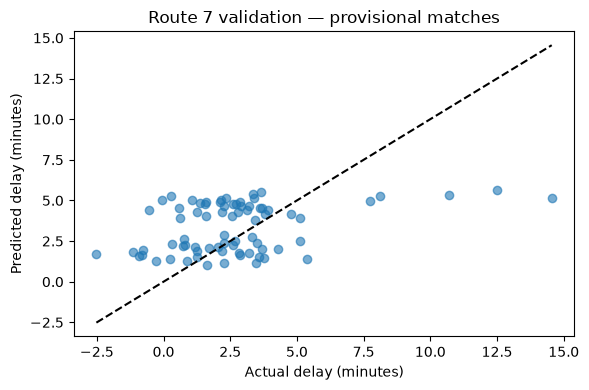

In [19]:
plt.figure(figsize=(6, 4))
plt.scatter(actual, predicted_delay, alpha=0.6)
low = min(actual.min(), predicted_delay.min())
high = max(actual.max(), predicted_delay.max())
plt.plot([low, high], [low, high], "k--")
plt.xlabel("Actual delay (minutes)")
plt.ylabel("Predicted delay (minutes)")
plt.title("Route 7 validation — provisional matches")
plt.tight_layout()
plt.show()

## Stage 6 — Assess predictors and document research decisions

**Input:** fitted regression, training design matrix, and validation results.  
**Purpose:** investigate fit, complexity, and redundant predictors, then explain the scope of conclusions.  
**Output:** regression diagnostics, VIF results where applicable, and written research decisions.

### 6.1 Optional regression diagnostics

The first model is complete. Use this section only if there is time.

| Measure | What it helps us ask |
| --- | --- |
| Validation MAE / R² | Does the model predict later observations well? |
| Training adjusted R² | How does training fit change after accounting for predictor count? |
| Training AIC / BIC | Is a suitable regression specification's fit worth its complexity? Compare on the same target and training rows. |
| VIF | Are encoded predictors redundant? |

AIC/BIC do not compare this model with random forest. For different model families, use the same validation dates and error measures. Do not choose features from final-test results.

In [20]:
display(pd.Series({
    "training_R2": model.rsquared,
    "training_adjusted_R2": model.rsquared_adj,
    "training_AIC": model.aic,
    "training_BIC": model.bic,
}).to_frame("regression_diagnostic"))

print("Encoded columns:", X_train.shape[1], "Design rank:", np.linalg.matrix_rank(X_train))

,regression_diagnostic
training_R2,0.309816
training_adjusted_R2,0.289257
training_AIC,1105.441815
training_BIC,1133.386306


Encoded columns: 8 Design rank: 8


### 6.2 Optional collinearity assessment using VIF

VIF includes the intercept when calculating redundancy, but we report only predictor VIFs. If the design rank is smaller than its column count, simplify the redundant inputs first.

Use these measures for discussion, not as automatic deletion rules. Stop visits are correlated within buses/journeys/dates, so standard OLS p-values are not reliable evidence of independent or causal effects.

In [21]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

if np.linalg.matrix_rank(X_train) < X_train.shape[1]:
    print("Redundant columns: review the chosen predictors before interpreting coefficients or VIF.")
else:
    vif = pd.DataFrame({
        "encoded_predictor": X_train.columns[1:],
        "VIF": [variance_inflation_factor(X_train.to_numpy(), i) for i in range(1, X_train.shape[1])],
    })
    display(vif)

,encoded_predictor,VIF
0,scheduled_hour,1.116247
1,stop_id_107,1.148767
2,direction_id_1,1.030807
3,weekday_Monday,1.671017
4,weekday_Thursday,1.680171
5,weekday_Tuesday,1.671488
6,weekday_Wednesday,1.680171


### 6.3 Record the research decisions and limitations

Edit this cell with your group's answers:

1. **A cleaning decision and its justification:**
2. **One proposed schedule match we checked, and evidence for/against it:**
3. **Which observations our matching rules exclude and how that can bias results:**
4. **Why each chosen predictor would be known before arrival:**
5. **Whether regression beat the schedule on validation MAE:**
6. **What changed when we removed/added scheduled hour or weekday:**
7. **What must be verified before treating these results as project findings:**

Save your notebook. It does not change either input file or write any extra files.

Next research step: improve schedule-match verification and compare random forest using the same Route 7 rows and dates. Keep the final-test dates reserved. We are not adding other routes in this workbook.

**Data sources:** Route 7 ride-check data deposited by Richard Borzi, University of Florida, supplied by Gainesville RTS; [Zenodo](https://zenodo.org/records/10034933), CC BY 4.0. Schedule read directly from [Spring 2023 GTFS](https://www.ftis.org/PostFileDownload.aspx?id=602A0), using service calendars and exceptions for the dates in the actual workbook. Neither current schedules nor interpolated intermediate times were substituted.

## Stage 7 - Additional checks on the matches already created

**Start here after finishing the original Stage 6.** We reuse `data`, `matched`, `schedule`, and the GTFS tables already in memory. We do not reload either file or rebuild the original merge.

The first pass in 2.5 checked unique nearby timetable candidates. We now add journey-order and other-timepoint checks, and separate terminal arrivals from departures. These are new reliability checks, not a repeat of the initial field cleaning.

The next helper-function cells are technical support. Focus first on their explanations and output tables. Schedule assignments remain provisional even after these checks. Historical corroboration must not be used as future information in a real-time predictor.

### Journey checks — Inspect complete source-order journey blocks
### 1.1 Restrict dates and reconstruct candidate blocks

We preserve the original file order within each bus/day. A decrease in stop sequence starts a new source block. This is independent of assigning a scheduled hour using the target arrival.

We compare recorded stop IDs and positions with complete GTFS trip patterns. Invalid/sentinel positions are not evidence of a correct route, even if the remaining positions agree. Blocks are still inferred, not source-provided trip IDs.

In [22]:
# Audit development dates only. Do not use final-test outcomes to change rules.
development_dates=sorted(data.service_date.dropna().unique())[:13]
dev=data[data.service_date.isin(development_dates)].sort_values(['bus_id','service_date','source_row']).copy()
planned=schedule[schedule.service_date.isin(development_dates)].copy()
matched=matched[matched.service_date.isin(development_dates)].copy()
g=dev.groupby(['bus_id','service_date'],sort=False)
dev['new_source_block']=g.cumcount().eq(0)|dev.stop_sequence.lt(g.stop_sequence.shift())
dev['block_number']=dev.groupby(['bus_id','service_date'])['new_source_block'].cumsum()
dev['block_id']=dev.bus_id.astype(str)+'|'+dev.service_date.dt.strftime('%Y-%m-%d')+'|'+dev.block_number.astype(str)
blocks=dict(tuple(dev.groupby('block_id',sort=False)))
block_by_source=dev.set_index('source_row').block_id
trip_patterns=route7_trips.merge(stop_times,on='trip_id')
trip_patterns['seq']=pd.to_numeric(trip_patterns.stop_sequence)
full_patterns={tid:list(zip(t.sort_values('seq')['seq'],t.sort_values('seq').stop_id)) for tid,t in trip_patterns.groupby('trip_id')}
date_trips={d:t for d,t in planned.groupby('service_date')}



### 1.2 Check other timepoints without the target arrival

The helper functions use the target's **other** timepoints to check its proposed trip. The target's own time is excluded from that assignment check.

We distinguish two levels:
- All other unique anchors, including ambiguous terminal records: corroboration with a qualification.
- Only unflagged other anchors: stricter support, still not external ground truth.

At least five other stop positions must agree with the candidate pattern. If several scheduled trips fit, we keep the ambiguity. A whole-hour shift can still fool all anchors, so these checks are not proof of identity.

In [23]:
def timepoint_anchors(block,target_sequence):
    """Other unique recorded timepoint positions, retaining ambiguity flags."""
    keys=planned[['stop_id','stop_sequence']].drop_duplicates()
    anchors=block.merge(keys,on=['stop_id','stop_sequence'],how='inner')
    anchors=anchors[anchors.stop_sequence.ne(target_sequence)&anchors.actual_arrival.notna()].copy()
    valid=anchors.groupby('stop_sequence').actual_arrival.transform('nunique').eq(1)
    return anchors[valid].drop_duplicates(['stop_sequence','stop_id','actual_arrival'])

def external_candidate_ids(anchors,observed_pattern,day):
    """Leave target arrival entirely out of the assignment check."""
    if anchors.empty or len(observed_pattern)<5:return []
    candidate_ids=[]
    for tid,t in date_trips[day].groupby('trip_id'):
        expected=dict(full_patterns[tid])
        if any(expected.get(seq)!=stop for seq,stop in observed_pattern):continue
        joined=anchors.merge(t[['stop_id','stop_sequence','scheduled_arrival']],on=['stop_id','stop_sequence'])
        if joined.stop_sequence.nunique()!=anchors.stop_sequence.nunique():continue
        offset=(joined.actual_arrival-joined.scheduled_arrival).dt.total_seconds()/60
        if offset.abs().le(20).all():candidate_ids.append(tid)
    return candidate_ids



### 1.3 Produce a row-by-row audit and check chronology

For each existing development match, record full/partial pattern agreement, original-time ordering, other-anchor support, and a suggested review action. Also check whether one source block claims multiple scheduled trips or scheduled time runs backward along original source order.

`hold` means unresolved, not confirmed wrong. No record is automatically promoted to verified.

In [24]:
audit_rows=[]
for visit in matched.itertuples():
    block=blocks[block_by_source.loc[visit.source_row]]
    ordinary=block[block.stop_sequence.between(0,31)&block.stop_id.ne('9999')]
    observed=list(dict.fromkeys(zip(ordinary.stop_sequence,ordinary.stop_id)))
    expected=full_patterns[visit.trip_id]
    expected_map=dict(expected)
    other_pattern=[(seq,stop) for seq,stop in observed if seq!=visit.stop_sequence]
    all_anchors=timepoint_anchors(block,visit.stop_sequence)
    strict=all_anchors[~all_anchors.needs_review]
    weak_ids=external_candidate_ids(all_anchors,other_pattern,visit.service_date)
    strict_ids=external_candidate_ids(strict,other_pattern,visit.service_date)
    if not all_anchors.empty and len(other_pattern)>=5:
        if len(weak_ids)==1:
            status='same_trip_supported_by_other_anchors' if weak_ids[0]==visit.trip_id else 'different_trip_suggested'
        elif len(weak_ids)>1:status='ambiguous_other_anchors'
        else:status='other_anchors_do_not_support_current_trip'
    else:status='insufficient_external_anchor_or_pattern_evidence'
    audit_rows.append({'source_row':visit.source_row,'date':str(visit.service_date.date()),'bus_id':visit.bus_id,
        'stop_id':visit.stop_id,'stop_sequence':visit.stop_sequence,'direction_id':visit.direction_id,
        'current_trip_id':visit.trip_id,'block_id':block_by_source.loc[visit.source_row],
        'full_ordered_pattern_matches':observed==expected,
        'pattern_mismatches':sum(expected_map.get(seq)!=stop for seq,stop in observed),
        'source_times_monotonic':block.actual_arrival.is_monotonic_increasing,
        'other_unique_timed_anchors':len(all_anchors),'other_unflagged_timed_anchors':len(strict),
        'external_candidate_count':len(weak_ids),'external_candidate_trip_ids':';'.join(weak_ids),
        'strict_external_candidate_count':len(strict_ids),
        'strict_same_trip_supported':len(strict_ids)==1 and strict_ids[0]==visit.trip_id,
        'external_check_status':status,
        'source_block_rows':','.join(str(int(x)) for x in block.source_row)})
linkage_audit=pd.DataFrame(audit_rows)
linkage_audit['recommended_review_action']='hold_terminal_dependent_corroboration'
linkage_audit.loc[linkage_audit.strict_same_trip_supported,'recommended_review_action']='priority_review_unflagged_anchor_support'
linkage_audit.loc[linkage_audit.stop_id.isin(['1','326']),'recommended_review_action']='hold_terminal_timestamp_semantics'
linkage_audit.loc[linkage_audit.external_check_status.ne('same_trip_supported_by_other_anchors'),'recommended_review_action']='hold_insufficient_independent_evidence'
matched_with_blocks=matched.copy()
matched_with_blocks['block_id']=matched_with_blocks.source_row.map(block_by_source)
block_trip_counts=matched_with_blocks.groupby('block_id').trip_id.nunique()
chronology=matched_with_blocks.sort_values(['bus_id','service_date','source_row'])
schedule_steps=chronology.groupby(['bus_id','service_date']).scheduled_arrival.diff()
chronology_inversions=int(schedule_steps.lt(pd.Timedelta(0)).sum())



In [25]:
display(linkage_audit["external_check_status"].value_counts().to_frame("visits"))
display(linkage_audit["recommended_review_action"].value_counts().to_frame("visits"))
print("Full-pattern agreements:", int(linkage_audit.full_ordered_pattern_matches.sum()))
print("Pattern contradictions:", int(linkage_audit.pattern_mismatches.gt(0).sum()))
print("Source blocks claiming multiple scheduled trips:", int(block_trip_counts.gt(1).sum()))
print("Scheduled-time inversions:", chronology_inversions)
display(linkage_audit[["source_row", "date", "bus_id", "stop_id", "current_trip_id",
    "other_unique_timed_anchors", "other_unflagged_timed_anchors", "recommended_review_action"]].head(10))

,visits
external_check_status,
same_trip_supported_by_other_anchors,316
insufficient_external_anchor_or_pattern_evidence,2


,visits
recommended_review_action,
hold_terminal_dependent_corroboration,292
hold_terminal_timestamp_semantics,12
priority_review_unflagged_anchor_support,12
hold_insufficient_independent_evidence,2


Full-pattern agreements: 295
Pattern contradictions: 0
Source blocks claiming multiple scheduled trips: 0
Scheduled-time inversions: 0


,source_row,date,bus_id,stop_id,current_trip_id,other_unique_timed_anchors,other_unflagged_timed_anchors,recommended_review_action
0,0,2023-03-01,2105,1,4059089,2,1,hold_terminal_timestamp_semantics
1,13,2023-03-01,2105,107,4059089,2,1,priority_review_unflagged_anchor_support
2,50,2023-03-01,2105,107,4059101,2,0,hold_terminal_dependent_corroboration
3,77,2023-03-01,2105,107,4059090,2,0,hold_terminal_dependent_corroboration
4,114,2023-03-01,2105,107,4059102,2,0,hold_terminal_dependent_corroboration
5,141,2023-03-01,2105,107,4059091,2,0,hold_terminal_dependent_corroboration
6,178,2023-03-01,2105,107,4059103,2,0,hold_terminal_dependent_corroboration
7,205,2023-03-01,2105,107,4059092,2,0,hold_terminal_dependent_corroboration
8,242,2023-03-01,2105,107,4059104,2,0,hold_terminal_dependent_corroboration
9,269,2023-03-01,2105,107,4059093,2,0,hold_terminal_dependent_corroboration


### 1.4 Inspect terminal transitions and destination-arrival candidates

A stop-sequence **31 → 0** transition can describe the end of one journey and start of the next at the same physical terminal. Sharing a timestamp is not automatically corrupt data.

**Arrival and departure must be separated.** A bus may arrive before its next scheduled departure and wait. The source `Arrive` field does not supply the actual departure time. We should not interpret an origin's early arrival as early departure.

The code below proposes destination-arrival records for review where the complete source pattern agrees, times are nondecreasing, and an unflagged **Health Department** visit independently links the trip. It does not use the destination target time to choose the scheduled trip and does not impose the 20-minute target filter.

These are recovery candidates, not approved labels. Duplicate destination records sharing one arrival are coalesced for this proposal only, with all source rows retained; passenger fields are not merged or interpreted.

In [26]:
# Independent source-order evidence for terminal timestamp interpretation.
dev['next_stop_id']=dev.groupby(['bus_id','service_date']).stop_id.shift(-1)
dev['next_sequence']=dev.groupby(['bus_id','service_date']).stop_sequence.shift(-1)
dev['next_arrival']=dev.groupby(['bus_id','service_date']).actual_arrival.shift(-1)
terminal_transition=dev.stop_sequence.eq(31)&dev.next_sequence.eq(0)
terminal_examples=dev.loc[terminal_transition,['source_row','bus_id','service_date','stop_id','actual_arrival','next_stop_id','next_arrival']].copy()
terminal_examples['same_stop']=terminal_examples.stop_id.eq(terminal_examples.next_stop_id)
terminal_examples['same_timestamp']=terminal_examples.actual_arrival.eq(terminal_examples.next_arrival)

# A shared end/start timestamp is not, by itself, evidence of an invalid arrival.
# Generate destination-arrival REVIEW candidates, using the non-terminal health
# timepoint for linkage and never filtering on the destination's observed delay.
endpoint_review_rows=[]
for block_id,block in blocks.items():
    ordinary=block[block.stop_sequence.between(0,31)&block.stop_id.ne('9999')]
    observed=list(dict.fromkeys(zip(ordinary.stop_sequence,ordinary.stop_id)))
    complete_ids=[tid for tid in date_trips[block.service_date.iloc[0]].trip_id.unique() if observed==full_patterns[tid]]
    if not complete_ids or not block.actual_arrival.is_monotonic_increasing:continue
    ends=ordinary[ordinary.stop_sequence.eq(31)]
    if ends.empty or ends.actual_arrival.nunique()!=1:continue
    endpoint=ends.iloc[0]
    anchors=timepoint_anchors(block,31)
    anchors=anchors[anchors.stop_id.eq('107')&~anchors.needs_review]
    ids=external_candidate_ids(anchors,[(seq,stop) for seq,stop in observed if seq!=31],endpoint.service_date)
    if len(ids)!=1:continue
    tid=ids[0]
    planned_end=planned[(planned.service_date==endpoint.service_date)&planned.trip_id.eq(tid)&planned.stop_sequence.eq(31)].iloc[0]
    offset=(endpoint.actual_arrival-planned_end.scheduled_arrival).total_seconds()/60
    endpoint_review_rows.append({'source_row':int(endpoint.source_row),'all_source_rows':','.join(str(int(x)) for x in ends.source_row),
        'date':str(endpoint.service_date.date()),'bus_id':endpoint.bus_id,'block_id':block_id,
        'stop_id':endpoint.stop_id,'stop_sequence':31,'trip_id':tid,'direction_id':planned_end.direction_id,
        'scheduled_arrival':planned_end.scheduled_arrival,'recorded_arrival':endpoint.actual_arrival,
        'offset_minutes_for_review_only':offset,'outside_original_20min_window':abs(offset)>20,
        'linking_anchor_source_rows':','.join(str(int(x)) for x in anchors.source_row),
        'was_in_current_modeling_table':endpoint.source_row in set(matched.source_row),
        'status':'destination_arrival_candidate_requires_manual_review'})
endpoint_review=pd.DataFrame(endpoint_review_rows)



In [27]:
print("Inspected terminal transitions:", len(terminal_examples))
print("Same stop and timestamp:", int((terminal_examples.same_stop & terminal_examples.same_timestamp).sum()))
display(terminal_examples.head(6))
print("Destination-arrival candidates for review:", len(endpoint_review))
if not endpoint_review.empty:
    display(endpoint_review.head(8))

Inspected terminal transitions: 291
Same stop and timestamp: 290


,source_row,bus_id,service_date,stop_id,actual_arrival,next_stop_id,next_arrival,same_stop,same_timestamp
7757,7757,1807,2023-03-14,1,2023-03-14 06:50:13,1,2023-03-14 06:50:13,True,True
7789,7789,1807,2023-03-14,326,2023-03-14 07:20:40,326,2023-03-14 07:20:40,True,True
7821,7821,1807,2023-03-14,1,2023-03-14 07:54:38,1,2023-03-14 07:54:38,True,True
7853,7853,1807,2023-03-14,326,2023-03-14 08:21:57,326,2023-03-14 08:21:57,True,True
7885,7885,1807,2023-03-14,1,2023-03-14 08:52:35,1,2023-03-14 08:52:35,True,True
7949,7949,1807,2023-03-14,1,2023-03-14 09:53:11,1,2023-03-14 09:53:11,True,True


Destination-arrival candidates for review: 283


,source_row,all_source_rows,date,bus_id,block_id,stop_id,stop_sequence,trip_id,direction_id,scheduled_arrival,recorded_arrival,offset_minutes_for_review_only,outside_original_20min_window,linking_anchor_source_rows,was_in_current_modeling_table,status
0,7789,7789,2023-03-14,1807,1807|2023-03-14|5,326,31,4059090,0,2023-03-14 07:20:00,2023-03-14 07:20:40,0.666667,False,7771,False,destination_arrival_candidate_requires_manual_...
1,7821,7821,2023-03-14,1807,1807|2023-03-14|6,1,31,4059102,1,2023-03-14 07:50:00,2023-03-14 07:54:38,4.633333,False,7808,False,destination_arrival_candidate_requires_manual_...
2,7853,7853,2023-03-14,1807,1807|2023-03-14|7,326,31,4059091,0,2023-03-14 08:20:00,2023-03-14 08:21:57,1.950000,False,7835,False,destination_arrival_candidate_requires_manual_...
3,7885,7885,2023-03-14,1807,1807|2023-03-14|8,1,31,4059103,1,2023-03-14 08:50:00,2023-03-14 08:52:35,2.583333,False,7872,False,destination_arrival_candidate_requires_manual_...
4,7917,7917,2023-03-14,1807,1807|2023-03-14|9,326,31,4059092,0,2023-03-14 09:20:00,2023-03-14 09:30:44,10.733333,False,7899,False,destination_arrival_candidate_requires_manual_...
5,7981,7981,2023-03-14,1807,1807|2023-03-14|12,326,31,4059093,0,2023-03-14 10:20:00,2023-03-14 10:20:29,0.483333,False,7963,False,destination_arrival_candidate_requires_manual_...
6,8013,8013,2023-03-14,1807,1807|2023-03-14|13,1,31,4059105,1,2023-03-14 10:50:00,2023-03-14 10:52:20,2.333333,False,8000,False,destination_arrival_candidate_requires_manual_...
7,8045,8045,2023-03-14,1807,1807|2023-03-14|14,326,31,4059094,0,2023-03-14 11:20:00,2023-03-14 11:30:59,10.983333,False,8027,False,destination_arrival_candidate_requires_manual_...


## Stage 8.1 — Define the arrival target and retain defensible records

Keep Health Department (`107`) arrivals with consistent stop order, nondecreasing source timestamps, and other-anchor corroboration. This retains 304 development visits from the earlier 318 proposed labels.

The removed labels comprise 13 origin visits and one unsupported destination visit. An origin's recorded arrival is not an actual departure time. We do not reinterpret early terminal arrivals as early departures.

Keep the audit status on every retained row. **Cleaned does not mean independently verified:** most scheduled-trip support still depends on terminal anchors. The GTFS `block_id` and our inferred source-block ID are different identifiers, so we rename them explicitly.

The split uses the same first ten training dates and next three validation dates. No later dates enter this output.

In [ ]:
import pandas as pd
import numpy as np

# Keep original data separate. Clean arrival targets, not origin departure targets.
development_dates = sorted(dev["service_date"].dropna().unique())
training_dates = development_dates[:10]
validation_dates = development_dates[10:13]

core = matched.rename(columns={"block_id": "gtfs_block_id"}).merge(
    linkage_audit[["source_row", "pattern_mismatches", "source_times_monotonic",
                   "full_ordered_pattern_matches", "strict_same_trip_supported",
                   "other_unflagged_timed_anchors", "external_check_status", "block_id"]].rename(columns={"block_id": "source_block_id"}),
    on="source_row", how="left", validate="one_to_one"
)
keep = (
    core["stop_id"].eq("107")
    & core["pattern_mismatches"].eq(0)
    & core["source_times_monotonic"].eq(True)
    & core["external_check_status"].eq("same_trip_supported_by_other_anchors")
)
cleaned_arrivals = core.loc[keep].copy()
cleaned_arrivals["delay_minutes"] = (
    cleaned_arrivals["actual_arrival"] - cleaned_arrivals["scheduled_arrival"]
).dt.total_seconds() / 60
cleaned_arrivals["split"] = np.where(
    cleaned_arrivals["service_date"].isin(training_dates), "train", "validation"
)
cleaned_arrivals["scheduled_hour"] = cleaned_arrivals["scheduled_arrival"].dt.hour
cleaned_arrivals["weekday"] = cleaned_arrivals["service_date"].dt.day_name()
cleaned_arrivals["linkage_status"] = np.where(
    cleaned_arrivals["strict_same_trip_supported"],
    "provisional: unflagged other-anchor support",
    "provisional: terminal-dependent support"
)


In [ ]:
display(cleaned_arrivals[["source_row", "bus_id", "service_date", "direction_id",
    "scheduled_arrival", "actual_arrival", "delay_minutes", "linkage_status"]].head(10))


print("Retained core visits:", len(cleaned_arrivals))

,source_row,bus_id,service_date,direction_id,scheduled_arrival,actual_arrival,delay_minutes,linkage_status
1,13,2105,2023-03-01,0,2023-03-01 06:08:00,2023-03-01 06:13:20,5.333333,provisional: unflagged other-anchor support
2,50,2105,2023-03-01,1,2023-03-01 06:40:00,2023-03-01 06:41:12,1.200000,provisional: terminal-dependent support
3,77,2105,2023-03-01,0,2023-03-01 07:08:00,2023-03-01 07:15:59,7.983333,provisional: terminal-dependent support
4,114,2105,2023-03-01,1,2023-03-01 07:40:00,2023-03-01 07:40:57,0.950000,provisional: terminal-dependent support
5,141,2105,2023-03-01,0,2023-03-01 08:08:00,2023-03-01 08:13:59,5.983333,provisional: terminal-dependent support
6,178,2105,2023-03-01,1,2023-03-01 08:40:00,2023-03-01 08:42:34,2.566667,provisional: terminal-dependent support
7,205,2105,2023-03-01,0,2023-03-01 09:08:00,2023-03-01 09:11:49,3.816667,provisional: terminal-dependent support
8,242,2105,2023-03-01,1,2023-03-01 09:40:00,2023-03-01 09:40:50,0.833333,provisional: terminal-dependent support
9,269,2105,2023-03-01,0,2023-03-01 10:08:00,2023-03-01 10:09:53,1.883333,provisional: terminal-dependent support
10,306,2105,2023-03-01,1,2023-03-01 10:40:00,2023-03-01 10:45:47,5.783333,provisional: terminal-dependent support


Retained core visits: 304


## Stage 8.2 — Preserve excluded records and their reasons

Every recorded timepoint outside the core goes into `held_records`; nothing disappears without a reason.

- Origin arrival: not suitable as an actual-departure target.
- Destination recovery candidate: needs manual timestamp/trip review.
- Other unresolved journey evidence: do not force a label.
- Flagged Health Department record: retain for investigation.

Stops without an explicit published time are outside the arrival-delay target population, not assumed to be bad observations. The raw workbook still contains them.

In [30]:
# Retain every timed observation outside the core, with a reason.
timed_keys = planned[["service_date", "stop_id", "stop_sequence"]].drop_duplicates()
timed_records = dev.merge(timed_keys, on=["service_date", "stop_id", "stop_sequence"], validate="many_to_one")
held_records = timed_records.loc[~timed_records["source_row"].isin(cleaned_arrivals["source_row"])].copy()
held_records["hold_reason"] = "unresolved_record_or_journey_evidence"
held_records.loc[held_records["stop_sequence"].eq(0), "hold_reason"] = "origin_arrival_is_not_actual_departure"
pending_endpoint_ids = set(endpoint_review["source_row"])
held_records.loc[held_records["source_row"].isin(pending_endpoint_ids), "hold_reason"] = "destination_arrival_pending_review"
held_records.loc[held_records["stop_id"].eq("107"), "hold_reason"] = "health_department_record_flagged_for_review"

# Attach proposed schedule references only where they actually exist.
links = pd.concat([
    matched[["source_row", "trip_id", "scheduled_arrival"]],
    endpoint_review[["source_row", "trip_id", "scheduled_arrival"]],
], ignore_index=True).drop_duplicates("source_row")
held_records = held_records.merge(links, on="source_row", how="left", validate="one_to_one")



In [31]:
display(held_records["hold_reason"].value_counts().to_frame("timed_records"))
display(held_records[["source_row", "bus_id", "service_date", "stop_id", "actual_arrival", "hold_reason"]].head(8))

,timed_records
hold_reason,
origin_arrival_is_not_actual_departure,352
destination_arrival_pending_review,283
unresolved_record_or_journey_evidence,21
health_department_record_flagged_for_review,1


,source_row,bus_id,service_date,stop_id,actual_arrival,hold_reason
0,7694,1807,2023-03-14,1,2023-03-14 05:52:03,origin_arrival_is_not_actual_departure
1,7708,1807,2023-03-14,107,2023-03-14 06:08:05,health_department_record_flagged_for_review
2,7725,1807,2023-03-14,326,2023-03-14 06:30:43,unresolved_record_or_journey_evidence
3,7727,1807,2023-03-14,326,2023-03-14 06:30:43,origin_arrival_is_not_actual_departure
4,7757,1807,2023-03-14,1,2023-03-14 06:50:13,unresolved_record_or_journey_evidence
5,7758,1807,2023-03-14,1,2023-03-14 06:50:13,origin_arrival_is_not_actual_departure
6,7789,1807,2023-03-14,326,2023-03-14 07:20:40,destination_arrival_pending_review
7,7790,1807,2023-03-14,326,2023-03-14 07:20:40,origin_arrival_is_not_actual_departure


## Stage 8.3 — Flag unusual delays using training data only

Use a separate IQR fence for each direction:

**IQR = training 75th percentile − training 25th percentile**  
**Lower fence = Q1 − 1.5 × IQR; upper fence = Q3 + 1.5 × IQR**

Apply those frozen training thresholds to both training and validation records. A value outside the fence is unusual, not proven incorrect. Do not delete genuine late/early arrivals just to improve R².

The outlier flag, fences, recorded actual arrival, and linkage status are audit fields. They must never become predictors: some are calculated from the target outcome.

In [32]:
# Statistical screening uses training outcomes only, separately by direction.
# Flags identify unusual values; no observation is deleted for being extreme.
training_core = cleaned_arrivals.loc[cleaned_arrivals["split"].eq("train")]
fence_rows = []
for direction, group in training_core.groupby("direction_id"):
    q1 = group["delay_minutes"].quantile(0.25)
    q3 = group["delay_minutes"].quantile(0.75)
    iqr = q3 - q1
    fence_rows.append({"direction_id": direction, "training_rows": len(group),
        "q1_minutes": q1, "q3_minutes": q3, "iqr_minutes": iqr,
        "iqr_low_minutes": q1 - 1.5 * iqr, "iqr_high_minutes": q3 + 1.5 * iqr})
training_fences = pd.DataFrame(fence_rows)
cleaned_arrivals = cleaned_arrivals.merge(
    training_fences[["direction_id", "iqr_low_minutes", "iqr_high_minutes"]],
    on="direction_id", how="left", validate="many_to_one"
)
cleaned_arrivals["iqr_outlier_flag"] = (
    cleaned_arrivals["delay_minutes"].lt(cleaned_arrivals["iqr_low_minutes"])
    | cleaned_arrivals["delay_minutes"].gt(cleaned_arrivals["iqr_high_minutes"])
)
outlier_review = cleaned_arrivals.loc[cleaned_arrivals["iqr_outlier_flag"]].copy()
outlier_review["review_decision"] = "retained: unusual delay, no confirmed measurement error"

cleaned_arrivals = cleaned_arrivals.sort_values(["service_date", "bus_id", "scheduled_arrival"]).reset_index(drop=True)
held_records = held_records.sort_values(["service_date", "bus_id", "source_row"]).reset_index(drop=True)

cleaning_counts = pd.Series({
    "development_raw_stop_visits": len(dev),
    "explicit_timed_stop_records": len(timed_records),
    "original_proposed_delay_labels": len(matched),
    "cleaned_core_arrival_labels": len(cleaned_arrivals),
    "removed_from_original_proposed_labels": len(matched) - len(cleaned_arrivals),
    "held_timed_records": len(held_records),
    "training_core_labels": int(cleaned_arrivals["split"].eq("train").sum()),
    "validation_core_labels": int(cleaned_arrivals["split"].eq("validation").sum()),
    "unusual_training_delays_flagged_and_kept": int((cleaned_arrivals["split"].eq("train") & cleaned_arrivals["iqr_outlier_flag"]).sum()),
    "unusual_validation_delays_flagged_and_kept": int((cleaned_arrivals["split"].eq("validation") & cleaned_arrivals["iqr_outlier_flag"]).sum()),
    "rows_removed_solely_for_extreme_delay": 0,
}, name="count")

assert cleaned_arrivals["source_row"].is_unique
assert not cleaned_arrivals.duplicated(["service_date", "trip_id", "stop_sequence"]).any()
assert cleaned_arrivals["stop_sequence"].gt(0).all()
assert cleaned_arrivals["stop_id"].eq("107").all()
assert len(cleaned_arrivals) + len(held_records) == len(timed_records)
assert set(cleaned_arrivals["source_row"]).isdisjoint(held_records["source_row"])
assert cleaned_arrivals["iqr_low_minutes"].notna().all()
assert cleaned_arrivals["service_date"].max() == pd.Timestamp("2023-03-17")


In [33]:
display(training_fences)
display(cleaning_counts.to_frame())
display(outlier_review[["source_row", "service_date", "direction_id", "split", "delay_minutes",
                        "iqr_low_minutes", "iqr_high_minutes", "review_decision"]])

,direction_id,training_rows,q1_minutes,q3_minutes,iqr_minutes,iqr_low_minutes,iqr_high_minutes
0,0,115,2.775000,6.108333,3.333333,-2.225000,11.108333
1,1,117,0.716667,2.366667,1.650000,-1.758333,4.841667


,count
development_raw_stop_visits,11280
explicit_timed_stop_records,961
original_proposed_delay_labels,318
cleaned_core_arrival_labels,304
removed_from_original_proposed_labels,14
held_timed_records,657
training_core_labels,232
validation_core_labels,72
unusual_training_delays_flagged_and_kept,5
unusual_validation_delays_flagged_and_kept,5


,source_row,service_date,direction_id,split,delay_minutes,iqr_low_minutes,iqr_high_minutes,review_decision
9,306,2023-03-01,1,train,5.783333,-1.758333,4.841667,"retained: unusual delay, no confirmed measurem..."
187,6885,2023-03-13,1,train,4.933333,-1.758333,4.841667,"retained: unusual delay, no confirmed measurem..."
192,7050,2023-03-13,1,train,-5.766667,-1.758333,4.841667,"retained: unusual delay, no confirmed measurem..."
196,7172,2023-03-13,1,train,9.250000,-1.758333,4.841667,"retained: unusual delay, no confirmed measurem..."
198,7236,2023-03-13,1,train,5.200000,-1.758333,4.841667,"retained: unusual delay, no confirmed measurem..."
233,8637,2023-03-15,1,validation,5.100000,-1.758333,4.841667,"retained: unusual delay, no confirmed measurem..."
251,9219,2023-03-15,1,validation,5.366667,-1.758333,4.841667,"retained: unusual delay, no confirmed measurem..."
267,9866,2023-03-16,1,validation,-2.516667,-1.758333,4.841667,"retained: unusual delay, no confirmed measurem..."
280,10401,2023-03-17,0,validation,12.516667,-2.225000,11.108333,"retained: unusual delay, no confirmed measurem..."
288,10657,2023-03-17,0,validation,14.550000,-2.225000,11.108333,"retained: unusual delay, no confirmed measurem..."


## Stage 9.1 - Pool buses and choose predictors

`direction_id` and `weekday` are categories; hour is numeric. Bus IDs identify records for error review but are not predictors. Actual arrival, outlier flags, linkage fields, and source identifiers are excluded. Only pre-arrival information enters the model.

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features = ["direction_id", "scheduled_hour", "weekday"]
target = "delay_minutes"
train = cleaned_arrivals.loc[cleaned_arrivals.split.eq("train")].copy()
validation = cleaned_arrivals.loc[cleaned_arrivals.split.eq("validation")].copy()
assert train.service_date.max() < validation.service_date.min()
assert "bus_id" not in features
assert len(train) == 232 and len(validation) == 72
print("Training:", len(train), "Validation:", len(validation))
display(train[features + [target]].head())
display(cleaned_arrivals.groupby(["split", "service_date", "bus_id"]).size().rename("records").reset_index())

def make_model(name):
    preparation = ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), ["direction_id", "weekday"]),
        ("hour", StandardScaler(), ["scheduled_hour"])
    ])
    estimator = LinearRegression() if name == "Linear regression" else Ridge(alpha=100)
    return Pipeline([("prepare", preparation), ("model", estimator)])

def predict_method(name, training, evaluation):
    if name == "Published schedule":
        return np.zeros(len(evaluation))
    if name == "Training median":
        return np.repeat(training[target].median(), len(evaluation))
    fitted = make_model(name).fit(training[features], training[target])
    return fitted.predict(evaluation[features])

methods = ["Published schedule", "Training median", "Linear regression", "Ridge regression"]

Training: 232 Validation: 72


,direction_id,scheduled_hour,weekday,delay_minutes
0,0,6,Wednesday,5.333333
1,1,6,Wednesday,1.200000
2,0,7,Wednesday,7.983333
3,1,7,Wednesday,0.950000
4,0,8,Wednesday,5.983333


,split,service_date,bus_id,records
0,train,2023-03-01,2105,24
1,train,2023-03-02,2105,24
2,train,2023-03-03,2105,20
3,train,2023-03-06,2105,24
4,train,2023-03-07,2105,24
5,train,2023-03-08,2105,24
6,train,2023-03-09,2105,24
7,train,2023-03-10,2005,22
8,train,2023-03-13,2107,23
9,train,2023-03-14,1807,23


## Stage 9.2 - Compare models on expanding whole-date folds

Use only the ten training dates: train on the first four dates and validate on the next two, then expand to six/eight training dates. No day appears on both sides of a fold. Preprocessing is fitted inside each fold. Compare the schedule, median, linear regression, and a fixed ridge model; no hyperparameter search.

Select the lowest pooled out-of-fold MAE before evaluating the three reserved validation dates. Fold variation shows how stable the result is across days.

The earliest fold has not seen every weekday. Unseen weekday labels use the reference encoding, so their distinct effects cannot yet be estimated. Interpret this small-sample limitation explicitly.

In [35]:
dates = sorted(train.service_date.unique())
fold_rows = []
fold_predictions = []
for fold, end in enumerate([4, 6, 8], start=1):
    fold_train = train.loc[train.service_date.isin(dates[:end])]
    fold_valid = train.loc[train.service_date.isin(dates[end:end+2])]
    assert fold_train.service_date.max() < fold_valid.service_date.min()
    for name in methods:
        prediction = predict_method(name, fold_train, fold_valid)
        errors = np.abs(fold_valid[target].to_numpy() - prediction)
        fold_rows.append({"fold": fold, "method": name, "training_rows": len(fold_train),
            "validation_rows": len(fold_valid), "MAE_minutes": errors.mean(),
            "train_through": fold_train.service_date.max(), "validate_from": fold_valid.service_date.min()})
        part = fold_valid[["source_row", "service_date", target]].copy()
        part["method"] = name
        part["absolute_error_minutes"] = errors
        fold_predictions.append(part)
fold_scores = pd.DataFrame(fold_rows)
oof_predictions = pd.concat(fold_predictions, ignore_index=True)
cv_summary = oof_predictions.groupby("method").absolute_error_minutes.agg(["count", "mean"]).rename(columns={"mean": "MAE_minutes"}).sort_values("MAE_minutes")
selected_method = cv_summary.index[0]
display(fold_scores)
display(cv_summary)
print("Selected using training-date folds:", selected_method)

/workspaces/RTS-Project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/workspaces/RTS-Project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,fold,method,training_rows,validation_rows,MAE_minutes,train_through,validate_from
0,1,Published schedule,92,48,3.380903,2023-03-06,2023-03-07
1,1,Training median,92,48,1.969097,2023-03-06,2023-03-07
2,1,Linear regression,92,48,1.339256,2023-03-06,2023-03-07
3,1,Ridge regression,92,48,1.792361,2023-03-06,2023-03-07
4,2,Published schedule,140,46,3.314493,2023-03-08,2023-03-09
5,2,Training median,140,46,2.065942,2023-03-08,2023-03-09
6,2,Linear regression,140,46,1.433011,2023-03-08,2023-03-09
7,2,Ridge regression,140,46,1.804672,2023-03-08,2023-03-09
8,3,Published schedule,186,46,2.687319,2023-03-10,2023-03-13
9,3,Training median,186,46,1.896377,2023-03-10,2023-03-13


,count,MAE_minutes
method,,
Linear regression,140,1.631679
Ridge regression,140,1.837974
Training median,140,1.977024
Published schedule,140,3.131190


Selected using training-date folds: Linear regression


## Stage 9.3 - Refit on all training buses and evaluate validation dates

Every method uses the same 232 training and 72 validation observations. MAE is the average absolute error in minutes; RMSE gives larger errors more weight. Negative R² can occur even when a prediction is practically useful, so compare it with the simple baselines.

This table is exploratory: these validation dates have been inspected in earlier notebooks. Leave March 20–23 untouched for a later, frozen final evaluation.

In [36]:
score_rows = []
validation_predictions = validation[["source_row", "bus_id", "service_date", "direction_id", "scheduled_hour", target]].copy()
for name in methods:
    prediction = predict_method(name, train, validation)
    validation_predictions[name] = prediction
    score_rows.append({"method": name, "selected_by_training_folds": name == selected_method,
        "MAE_minutes": mean_absolute_error(validation[target], prediction),
        "RMSE_minutes": np.sqrt(mean_squared_error(validation[target], prediction)),
        "R2": r2_score(validation[target], prediction)})
validation_scores = pd.DataFrame(score_rows)
display(validation_scores.round(4))
selected_prediction = validation_predictions[selected_method]
validation_predictions["prediction_minutes"] = selected_prediction
validation_predictions["signed_error_minutes"] = selected_prediction - validation[target]
validation_predictions["absolute_error_minutes"] = validation_predictions.signed_error_minutes.abs()

,method,selected_by_training_folds,MAE_minutes,RMSE_minutes,R2
0,Published schedule,False,2.7120,3.5833,-0.9748
1,Training median,False,1.6333,2.5501,-0.0002
2,Linear regression,True,2.0821,2.6521,-0.0818
3,Ridge regression,False,1.7494,2.4952,0.0424


## Stage 10.1 - Inspect errors by bus, date, and direction

Positive signed error means predicting more delay than occurred. Always show record counts. Because each date has one recorded bus, bus differences cannot establish a vehicle effect. These summaries diagnose weaknesses; do not delete validation records because their errors are large.

Errors by bus_id


,records,MAE_minutes,bias_minutes
bus_id,,,
2104,24,2.233,1.763
2107,48,2.007,0.166


Errors by service_date


,records,MAE_minutes,bias_minutes
service_date,,,
2023-03-15,24,1.926,0.278
2023-03-16,24,2.233,1.763
2023-03-17,24,2.087,0.055


Errors by direction_id


,records,MAE_minutes,bias_minutes
direction_id,,,
0,36,2.675,1.525
1,36,1.489,-0.128


Errors by scheduled_hour


,records,MAE_minutes,bias_minutes
scheduled_hour,,,
6,6,2.924,-1.200
7,6,1.916,1.167
8,6,1.922,1.922
9,6,2.421,2.211
10,6,3.093,-0.813
11,6,2.833,2.434
12,6,2.018,1.637
13,6,2.169,0.048
14,6,1.174,0.315


,source_row,bus_id,service_date,direction_id,scheduled_hour,delay_minutes,Published schedule,Training median,Linear regression,Ridge regression,prediction_minutes,signed_error_minutes,absolute_error_minutes
288,10657,2107,2023-03-17,0,10,14.550000,0.0,2.55,4.959290,3.678721,4.959290,-9.590710,9.590710
280,10401,2107,2023-03-17,0,6,12.516667,0.0,2.55,5.458628,4.024055,5.458628,-7.058038,7.058038
268,9893,2104,2023-03-16,0,12,-0.533333,0.0,2.55,4.601103,3.555077,4.601103,5.134437,5.134437
290,10721,2107,2023-03-17,0,11,-0.050000,0.0,2.55,4.834455,3.592387,4.834455,4.884455,4.884455
286,10593,2107,2023-03-17,0,9,0.283333,0.0,2.55,5.084125,3.765054,5.084125,4.800791,4.800791
267,9866,2104,2023-03-16,1,11,-2.516667,0.0,2.55,1.681536,2.523300,1.681536,4.198202,4.198202
266,9829,2104,2023-03-16,0,11,0.566667,0.0,2.55,4.725938,3.641410,4.725938,4.159271,4.159271
258,9562,2104,2023-03-16,0,7,1.066667,0.0,2.55,5.225276,3.986744,5.225276,4.158609,4.158609
251,9219,2107,2023-03-15,1,15,5.366667,0.0,2.55,1.297822,2.215466,1.297822,-4.068844,4.068844
260,9637,2104,2023-03-16,0,8,1.600000,0.0,2.55,5.100441,3.900411,5.100441,3.500441,3.500441


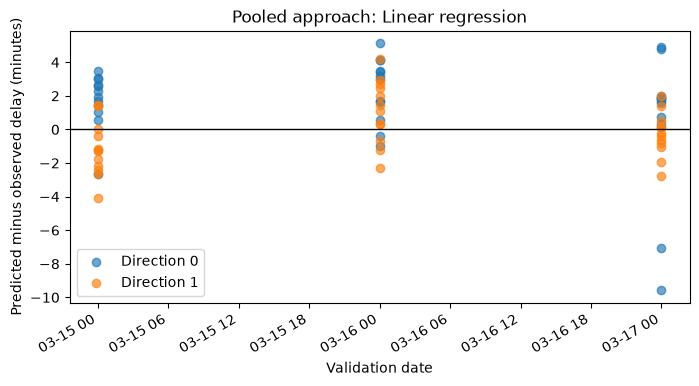

In [37]:
error_tables = {}
for group in ["bus_id", "service_date", "direction_id", "scheduled_hour"]:
    table = validation_predictions.groupby(group).agg(
        records=("absolute_error_minutes", "size"),
        MAE_minutes=("absolute_error_minutes", "mean"),
        bias_minutes=("signed_error_minutes", "mean"))
    error_tables[group] = table
    print("Errors by", group)
    display(table.round(3))
display(validation_predictions.nlargest(10, "absolute_error_minutes"))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
for direction, part in validation_predictions.groupby("direction_id"):
    ax.scatter(part.service_date, part.signed_error_minutes, label=f"Direction {direction}", alpha=0.65)
ax.axhline(0, color="black", linewidth=1)
ax.set(ylabel="Predicted minus observed delay (minutes)", xlabel="Validation date", title=f"Pooled approach: {selected_method}")
ax.legend()
fig.autofmt_xdate()
plt.show()

## Stage 10.2 — Read the result in plain language

The **published schedule** predicts zero delay. The **training median** adds the typical historical delay to every scheduled arrival. Linear regression learns coefficients for direction, weekday, and hour; ridge shrinks coefficients to reduce instability.

A model can win on training-date folds and lose on later validation dates. Report both results. Do not select features repeatedly using the same validation outcomes and then call that validation a fresh test.

Published schedule MAE: 2.71 minutes
Historical median MAE: 1.63 minutes
Median reduction in MAE: 39.8%
Training-fold choice: Linear regression
Lowest validation MAE: Training median


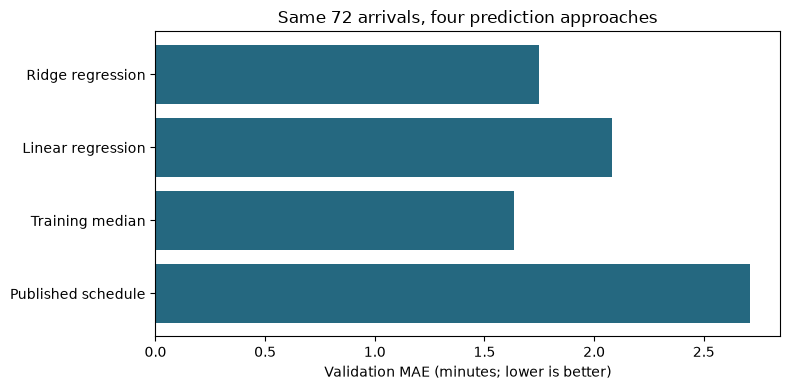

In [38]:
median_mae = validation_scores.set_index("method").loc["Training median", "MAE_minutes"]
schedule_mae = validation_scores.set_index("method").loc["Published schedule", "MAE_minutes"]
print(f"Published schedule MAE: {schedule_mae:.2f} minutes")
print(f"Historical median MAE: {median_mae:.2f} minutes")
print(f"Median reduction in MAE: {100 * (1 - median_mae / schedule_mae):.1f}%")
print("Training-fold choice:", selected_method)
print("Lowest validation MAE:", validation_scores.loc[validation_scores.MAE_minutes.idxmin(), "method"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(validation_scores.method, validation_scores.MAE_minutes, color="#256880")
ax.set(xlabel="Validation MAE (minutes; lower is better)", title="Same 72 arrivals, four prediction approaches")
fig.tight_layout()
plt.show()

## Stage 10.3 — Conclusions and the next route experiment

### What we can conclude
The historical median adjustment improves on the timetable in this validation sample. The fitted models do not beat that median here. That is a useful research result: extra complexity needs evidence.

### What remains uncertain
- Schedule links remain provisional; most depend on terminal evidence.
- There is only one modeled stop, 13 development dates, and no weekends.
- Each observed date contains one bus, so bus and date effects cannot be separated reliably.
- Validation is only three days and has been inspected in earlier experiments.
- No final-test result is reported. March 20–23 must remain untouched until linkage rules, predictors, and selection procedure are frozen.

### Before the final test
Record the chosen selection rule and model settings, resolve label concerns without choosing rules to improve test scores, fit on the approved development data, then score the final test once. Present this notebook as a completed **development analysis**, not an independently verified operational system.

### Questions for the next meeting: which routes do we study next?
1. Should we start with Route 3, 11, or 711? Which has usable dates, stop identifiers, and a compatible historical schedule?
2. Can we reproduce the cleaning and schedule checks before fitting that route?
3. Will we first fit a **separate model per route**, or pool compatible records with route/direction/stop identifiers? Why?
4. If we pool routes, how will we distinguish stop/direction patterns that have different meanings on different routes?
5. Can we use the **same whole-calendar-date splits across all routes**? What should we do if observed dates do not overlap?
6. Does each route beat its own schedule and training-median baselines? Show counts and errors per route, not just an overall average.
7. Would a pooled model mainly benefit the route with the largest sample? How should we report that?
8. What would justify trying random forest next? What result would justify retaining the simpler median?
9. If we later add recent delay, what is the exact prediction timestamp, and can every feature and its schedule assignment be obtained without later observations?

**Suggested next step:** repeat this pipeline on one additional route, first fit separate route models with the same evaluation rules, then test pooling as an extension. Keep the raw inputs unchanged and document each decision.

### Final record of the extension

Record your answers: did a model beat the median on later dates? Did the training-fold choice generalize? Which labels still need verification? Which route comes next, and will its first model be separate or pooled?

Predictors remain direction, scheduled hour, and weekday. Bus ID is diagnostic only. No recent-delay feature is added because its availability and schedule assignment at prediction time have not yet been demonstrated. Nothing here scores the final test. Freeze linkage rules, features, and model selection before that final evaluation.

## Save the development dataframe for Notebook 4

Run this last cell after the analysis above. It saves one new file beside this notebook. Notebook 4 reads that file in a fresh kernel; notebook variables do not automatically transfer. Only development dates are exported. Keep the column names and split labels unchanged.

In [39]:
handoff_columns = ["source_row", "bus_id", "service_date", "split", "stop_id", "direction_id",
    "scheduled_arrival", "actual_arrival", "delay_minutes", "scheduled_hour", "weekday", "linkage_status"]
assert cleaned_arrivals["service_date"].max() <= pd.Timestamp("2023-03-17")
cleaned_arrivals[handoff_columns].to_csv("Route7_Development.csv", index=False)
print("Saved Route7_Development.csv for Notebook 4:", len(cleaned_arrivals), "records")

Saved Route7_Development.csv for Notebook 4: 304 records
